# Dissolved oxygen electrode response time

A dissolved oxygen probe does not report a change in oxygen concentration instantly. When the probe is moved suddenly from one oxygen level to another, its reading approaches the new value gradually. If the probe behaves as a first-order system, the reading follows

$$y(t) = y_0 + (y_f - y_0)\left(1 - e^{-t/\tau_E}\right)$$

where $y_0$ is the reading at the moment of the step, $y_f$ is the final reading, and $\tau_E$ is the electrode response time: the time the probe takes to cover 63% of the change. This notebook fits that equation to each trial in your data file and reports $\tau_E$ with a 95% confidence interval, plots each fit against the data, and plots the residuals so you can judge whether the first-order model describes your probe.

The model assumes the step happens at $t = 0$, so the first row of your data should be the moment the probe was switched.

**To use it:** put your data file in the same folder as this notebook and set the file name in the settings cell. Then choose **Run → Run All Cells** from the menu. The cells depend on one another, so they must run in order from the top; running only a later cell gives a `NameError`. After changing a setting, run all cells again.

In [90]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, OptimizeWarning
from scipy.stats import t as t_dist

# Some notebook environments running Matplotlib 3.10 print harmless
# "parameter as float was deprecated" warnings when laying out figures.
warnings.filterwarnings("ignore", message=".*parameter as float was deprecated.*")

## 1. Settings

Change only this cell. The first column of the data file must be time, in seconds, whatever its header says. Every other column holds the probe readings for one trial and can have its own header, such as `Trial 1` or `Run A`. Trials of different lengths are fine: leave the unused cells at the bottom of a shorter trial blank.

In [92]:
DATA_FILE = "Electy1.csv"

# Label for the probe reading on the plots, including its units.
READING_LABEL = "DO reading (% air saturation)"

# Starting guess for the response time (s). Change it only if a fit fails.
TAU_GUESS = 30.0

# Trial shown in the representative figure in Section 7. Type its column header
# exactly, such as "Trial 1". Leave it as "" to use the first trial in the file.
REPRESENTATIVE_TRIAL = ""

# The representative figure is also saved to this file.
FIGURE_FILE = "tauE_representative_figure.png"

## 2. Load the data

In [94]:
if not os.path.exists(DATA_FILE):
    csv_files = sorted(f for f in os.listdir(".") if f.lower().endswith(".csv"))
    raise FileNotFoundError(
        f'Cannot find "{DATA_FILE}" in the folder this notebook is in.\n'
        f"CSV files in this folder: {', '.join(csv_files) if csv_files else 'none'}.\n"
        "Move your data file into this folder, or change DATA_FILE in the settings cell "
        "to match its name exactly."
    )
df = pd.read_csv(DATA_FILE)
df = df.dropna(axis="columns", how="all")         # ignore empty columns left over from Excel
TIME_COLUMN = df.columns[0]                         # the first column is always time
trial_columns = list(df.columns[1:])

trials = {}
for trial in trial_columns:
    rows = df[[TIME_COLUMN, trial]].dropna()          # skip blank cells in shorter trials
    trials[trial] = (rows[TIME_COLUMN].to_numpy(dtype=float),
                     rows[trial].to_numpy(dtype=float))
    t_trial = trials[trial][0]
    print(f"{trial}: {len(t_trial)} points from {t_trial.min():g} to {t_trial.max():g} s")

Trial 1: 10 points from 0 to 270 s
Trial 2: 10 points from 0 to 270 s
Trial 3: 10 points from 0 to 270 s


## 3. Model

In [96]:
def first_order(t, y0, yf, tau_E):
    # Probe reading after a step change at t = 0.
    return y0 + (yf - y0) * (1.0 - np.exp(-t / tau_E))

## 4. Fit each trial

For each trial, the fit adjusts $y_0$, $y_f$ and $\tau_E$ until the sum of squared residuals between the model and the readings is as small as possible. The 95% confidence interval for each fitted parameter is calculated the same way as for the slope of a linear fit: the standard error of the parameter multiplied by the critical $t$-value corresponding to your degrees of freedom ($n - p$, where $n$ is the total number of data points and $p$ is the number of fitted parameters).

This interval reflects only how closely one trial's readings scatter around its fitted curve. The spread of $\tau_E$ across replicate trials, calculated in Section 5, is the better measure of how reproducible your probe's response time is.

In [98]:
results = {}
for trial, (t_data, y_data) in trials.items():
    p0 = [y_data[0], y_data[-1], TAU_GUESS]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", OptimizeWarning)
            popt, pcov = curve_fit(first_order, t_data, y_data, p0=p0)
    except (RuntimeError, OptimizeWarning, ValueError) as err:
        print(f"{trial}: the fit failed ({err}). Try a different TAU_GUESS.")
        continue

    dof = len(t_data) - len(popt)
    half_width = t_dist.ppf(0.975, dof) * np.sqrt(np.diag(pcov))
    results[trial] = {"params": popt, "ci": half_width,
                      "residuals": y_data - first_order(t_data, *popt)}

print("Best-fit values with 95% confidence intervals\n")
for trial, r in results.items():
    (y0, yf, tau_E), (ci_y0, ci_yf, ci_tau) = r["params"], r["ci"]
    print(f"{trial}:  tau_E = {tau_E:.1f} ± {ci_tau:.1f} s   "
          f"(y0 = {y0:.1f} ± {ci_y0:.1f}, yf = {yf:.1f} ± {ci_yf:.1f})")

Best-fit values with 95% confidence intervals

Trial 1:  tau_E = 176.2 ± 61.9 s   (y0 = -2.7 ± 5.5, yf = 112.2 ± 20.6)
Trial 2:  tau_E = 178.9 ± 66.2 s   (y0 = -3.1 ± 5.7, yf = 113.3 ± 22.2)
Trial 3:  tau_E = 211.1 ± 112.2 s   (y0 = -4.3 ± 7.2, yf = 123.1 ± 38.2)


## 5. Response time across replicate trials

If your trials are replicates, meaning repeated steps under the same conditions, this cell averages $\tau_E$ across them and reports a 95% confidence interval from their spread, using the t value for the number of trials minus one. This is the same calculation as Excel's `CONFIDENCE.T`. 

In [100]:
tau_values = np.array([r["params"][2] for r in results.values()])
n = len(tau_values)
if n >= 2:
    mean_tau = tau_values.mean()
    sd_tau = tau_values.std(ddof=1)
    ci_tau = t_dist.ppf(0.975, n - 1) * sd_tau / np.sqrt(n)
    print(f"{n} trials: mean tau_E = {mean_tau:.1f} s, standard deviation = {sd_tau:.1f} s")
    print(f"95% confidence interval on the mean: {mean_tau:.1f} ± {ci_tau:.1f} s")
else:
    print("At least two successful fits are needed to compare replicate trials.")

3 trials: mean tau_E = 188.7 s, standard deviation = 19.4 s
95% confidence interval on the mean: 188.7 ± 48.3 s


## 6. Model and data

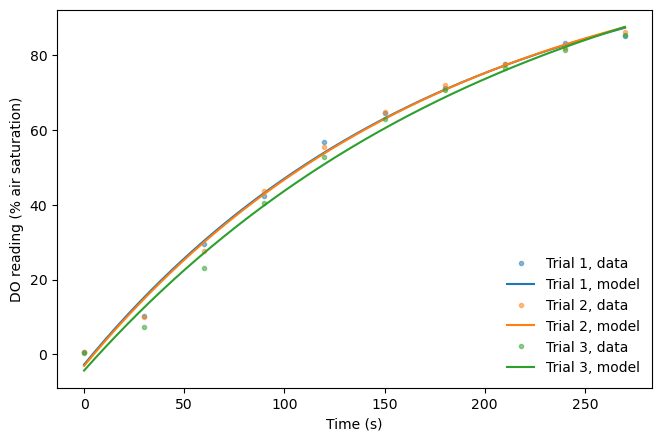

In [102]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, (trial, r) in enumerate(results.items()):
    t_data, y_data = trials[trial]
    color = f"C{i}"
    t_smooth = np.linspace(0.0, t_data.max(), 300)
    ax.plot(t_data, y_data, "o", markersize=3, alpha=0.5, color=color, label=f"{trial}, data")
    ax.plot(t_smooth, first_order(t_smooth, *r["params"]), "-", color=color, label=f"{trial}, model")

ax.set_xlabel("Time (s)")
ax.set_ylabel(READING_LABEL)
ax.legend(frameon=False, loc="lower right")
fig.subplots_adjust(left=0.12, right=0.97, bottom=0.12, top=0.96)
plt.show()

## 7. Representative figure

This is a representative figure showing one trial, with the readings shown as symbols and the fitted model as a line. Choose the trial in the settings cell with `REPRESENTATIVE_TRIAL`. The figure has no title because the caption you write in your report takes its place; state $\tau_E$ in that caption. The figure is saved at print resolution to the file named in `FIGURE_FILE`, in the same folder as this notebook.

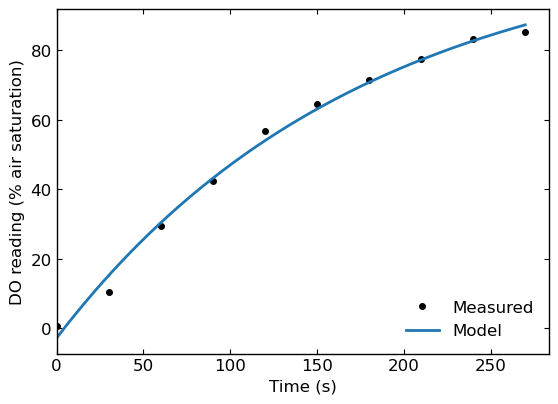

Trial 1: tau_E = 176.2 ± 61.9 s
Figure saved to tauE_representative_figure.png.


In [104]:
if REPRESENTATIVE_TRIAL == "":
    rep_trial = next(iter(results))
elif REPRESENTATIVE_TRIAL in results:
    rep_trial = REPRESENTATIVE_TRIAL
else:
    raise ValueError(
        f'"{REPRESENTATIVE_TRIAL}" is not one of the fitted trials. '
        f"Set REPRESENTATIVE_TRIAL to one of: {', '.join(results)}."
    )

r = results[rep_trial]
t_data, y_data = trials[rep_trial]
t_smooth = np.linspace(0.0, t_data.max(), 300)

with plt.rc_context({"font.size": 12, "axes.linewidth": 1.0}):
    fig, ax = plt.subplots(figsize=(6.0, 4.2))
    ax.plot(t_data, y_data, "o", markersize=4, color="black", label="Measured")
    ax.plot(t_smooth, first_order(t_smooth, *r["params"]), "-", color="C0",
            linewidth=2, label="Model")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(READING_LABEL)
    ax.set_xlim(left=0)
    ax.tick_params(direction="in", top=True, right=True)
    ax.legend(frameon=False, loc="lower right")
    fig.subplots_adjust(left=0.14, right=0.96, bottom=0.14, top=0.96)
    fig.savefig(FIGURE_FILE, dpi=300)
    plt.show()

print(f"{rep_trial}: tau_E = {r['params'][2]:.1f} ± {r['ci'][2]:.1f} s")
print(f"Figure saved to {FIGURE_FILE}.")

## 8. Residuals

A residual is the measured reading minus the model's prediction at the same time. If the first-order model describes your probe, the residuals scatter randomly above and below zero with no pattern and are small compared with the total change in the reading. Any pattern means the model is missing something real.

The most common pattern begins with a large positive residual. It means the reading began rising later or more slowly than the model allows, usually because the oxygen level around the probe did not change all at once, the probe took a few seconds to move, or the clock started early. Residuals that keep rising or falling long after the reading should have leveled off point to drift in the probe, and a residual that suddenly jumps and returns marks an event in the vessel, such as a bubble on the membrane or a bump to the probe. All panels share the same vertical scale: if every trial shows the same pattern, the cause lies in the probe or the procedure, and if only one does, something happened during that run.

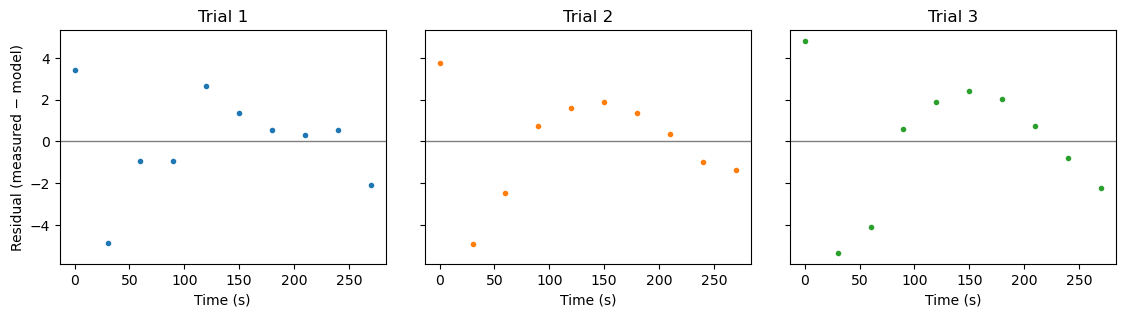

In [106]:
n_trials = len(results)
n_cols = min(n_trials, 3)
n_rows = int(np.ceil(n_trials / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows),
                         sharey=True, squeeze=False)

for ax, (i, (trial, r)) in zip(axes.flat, enumerate(results.items())):
    t_data = trials[trial][0]
    ax.axhline(0.0, color="gray", linewidth=1)
    ax.plot(t_data, r["residuals"], "o", markersize=3, color=f"C{i}")
    ax.set_title(trial)
    ax.set_xlabel("Time (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("Residual (measured − model)")
for ax in list(axes.flat)[n_trials:]:
    ax.set_visible(False)

fig.subplots_adjust(left=0.1, right=0.98, bottom=0.17 if n_rows == 1 else 0.1,
                    top=0.9 if n_rows == 1 else 0.94, wspace=0.12, hspace=0.45)
plt.show()